In [27]:
import matplotlib.pyplot as plt
plt.style.use('my_style')

# SAMPLE = 'CsPbBr3'
SAMPLES = [
    'sqs0-2x2x2_Cs2Pb2Br5Cl',
    'sqs0-2x2x2_Cs2Pb2BrCl5',
    'sqs0-2x2x2_Cs2Pb2Br5Cl',
    'sqs0-2x2x2_Cs2Pb2I5Br',
    'sqs0-2x2x2_Cs2Pb2IBr5',
    'sqs0-2x2x2_CsPbBr2Cl',
    'sqs0-2x2x2_CsPbI2Cl',
    'sqs0-2x2x2_Cs2Pb2(BrCl)3',
    'sqs0-2x2x2_Cs2Pb2I5Cl',
    'sqs0-2x2x2_Cs2Pb2(ICl)3',
    'sqs0-2x2x2_CsPbBrCl2',
    'sqs0-2x2x2_CsPbIBr2',
]
DIR_NAME = './mnt/mlip_phonons_mixed/MACE-matpes-r2scan-omat-ft'

data = []
for s in SAMPLES:
    with open(f'{DIR_NAME}/{s}/{s}.dos', 'r') as f:
        lines = f.readlines()[1:]
        data.append([list(map(float, line.split())) for line in lines])
        # print(len(data[-1]), 'lines read for', s)

# diff = [x0 - x1 for x0, x1 in zip([row[0] for row in data[0]], [row[0] for row in data[1]])]
# len(diff)

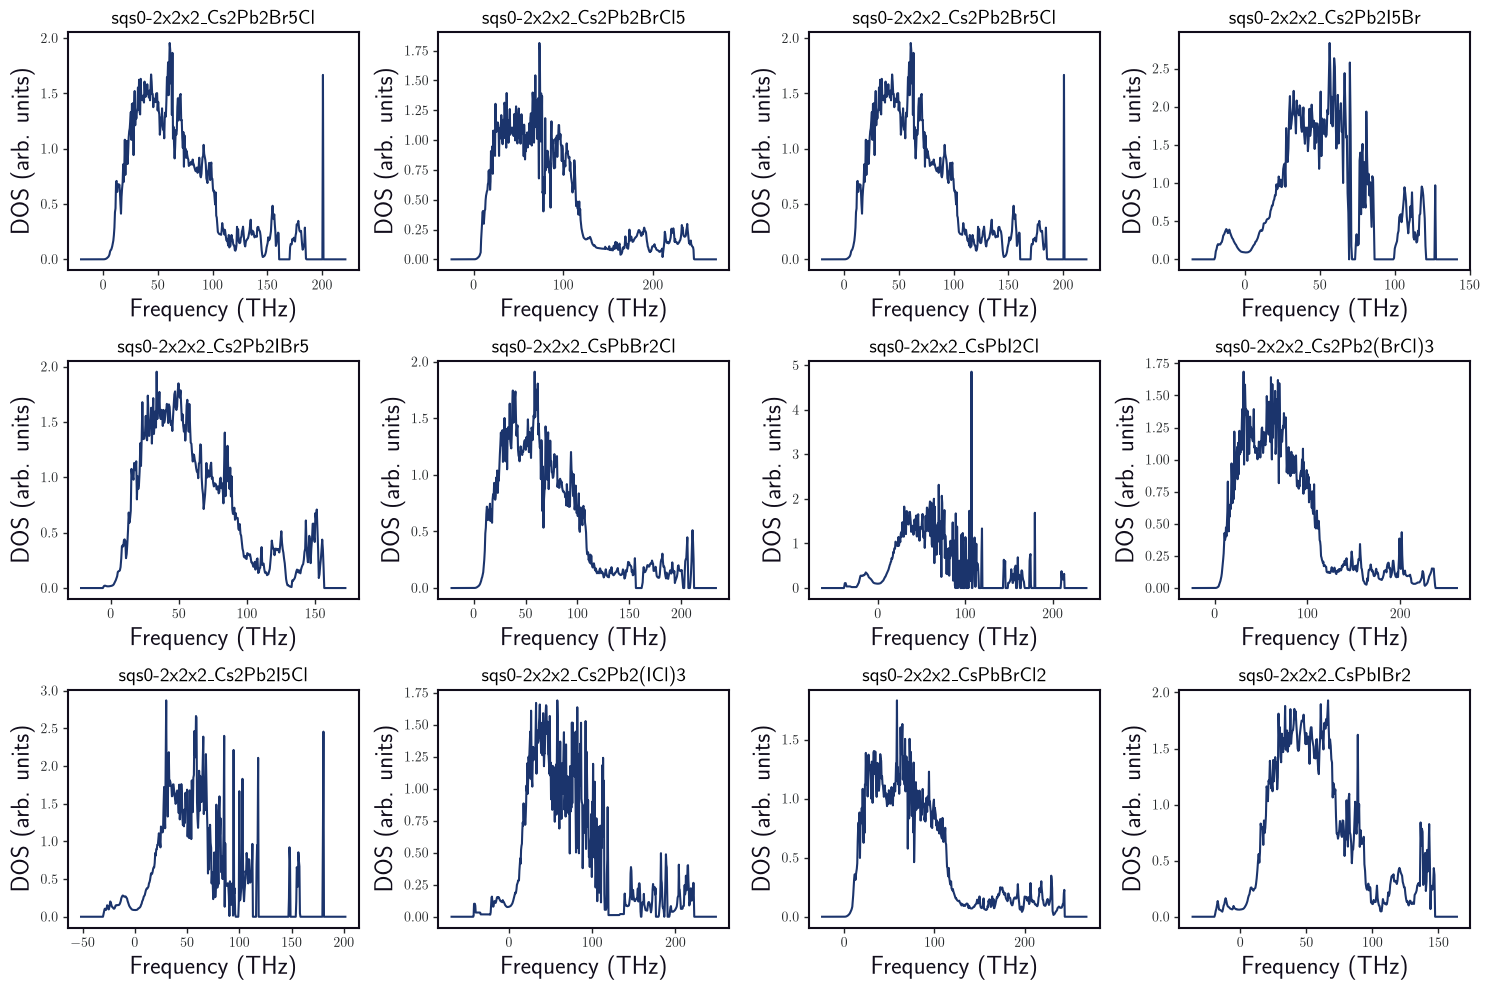

In [32]:
ncol = 4
nrow = len(SAMPLES) // ncol + (len(SAMPLES) % ncol > 0)
fig, axs = plt.subplots(nrow, ncol, figsize=(15, 10))
for i, d in enumerate(data):
    ax = axs[i // ncol, i % ncol]
    ax.plot([row[0] for row in d], [row[1] for row in d])
    ax.set_title(SAMPLES[i])
    ax.set_xlabel('Frequency (THz)')
    ax.set_ylabel('DOS (arb. units)')
plt.tight_layout()
# plt.savefig('dos_mixed.png', dpi=300)
plt.show()